In [1]:
# Cache-only setup and evidence diagnostics for cos_per_chunk_raw_analysis.ipynb.
# No feature loading, fitting, or modification of training artifacts.

from pathlib import Path
from itertools import product
from datetime import datetime, timezone
import hashlib
import json
import platform

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.isotonic import IsotonicRegression
from IPython.display import display

CACHE_VALIDATED = False
PREDICTIONS = {}
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/snr_sweep.py").is_file():
    raise RuntimeError("Open this notebook from the repository root or notebooks/.")

CACHE_ROOT = ROOT / "outputs/cos_lsf_snr/perchunk_tuned"
OUT = CACHE_ROOT / "raw_combination"
QA_SNAPSHOT = ROOT / "outputs/cos_observational_qa/qa_20261018T223903588165Z"
MANIFEST_PATH = ROOT / "outputs/uvb_mean_flux/manifests/z0_b15_seed42.npz"
BASELINE_PATH = ROOT / "outputs/cos_lsf_snr/snr_sweep/summary/bootstrap_inputs.npz"
AGGREGATION_SOURCE = "raw"
MODELS = ("EX0", "EX1", "EX2", "EX3")
SNRS = (10, 15, 20, 30, 50, 80)
NOISE_SEEDS = (20260929, 20260930, 20261001)
TASKS = {
    "EX0_EX3": ("EX0", "EX3"),
    "EX2_EX3": ("EX2", "EX3"),
    "EX0_EX2": ("EX0", "EX2"),
    "EX0_EX1": ("EX0", "EX1"),
    "four_class": MODELS,
}
TASK_LABELS = {t: "four-class" if len(m) == 4 else "–".join(m)
               for t, m in TASKS.items()}
PLOT_SNRS = (10, 20, 30, 50)
SEED = 20261011
EPS = 1e-6
DIRECT_DRAWS, DIRECT_MAX_N = 10_000, 200
GAUSSIAN_MAX_N, GAUSSIAN_SOBOL_POWER = 10_000, 15
CHECK_NS, CHECK_ABS_TOL = (50, 100, 150, 200), 0.02
BASELINE_BOOTSTRAPS = 5000


def require(condition, message):
    if not condition:
        raise ValueError(message)


def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def json_hash(value):
    # Identical serialization to the original training notebook.
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def read_json(path):
    with Path(path).open(encoding="utf-8") as handle:
        return json.load(handle)


def read_npz(path, required):
    with np.load(path, allow_pickle=False) as saved:
        missing = set(required) - set(saved.files)
        require(not missing, f"{path}: missing arrays {sorted(missing)}")
        return {key: saved[key] for key in required}


def integer_array(value, name, shape=None):
    a = np.asarray(value)
    require(a.dtype.kind in "iu", f"{name}: expected an integer array")
    if shape is not None:
        require(a.shape == shape, f"{name}: shape {a.shape}, expected {shape}")
    return a.astype(np.int64, copy=False)


def same_array(actual, expected, name):
    require(np.array_equal(actual, expected), f"{name}: values or ordering differ")


def valid_digest(value):
    return (isinstance(value, str) and len(value) == 64
            and all(c in "0123456789abcdef" for c in value))


def normalize_probabilities(p):
    # Preserve the original helper and EPS. Used ONLY to verify saved calibration.
    # Stored raw/calibrated predictions are never normalized or clipped again.
    p = np.asarray(p, dtype=float)
    if p.ndim == 1:
        p = np.column_stack([1-p, p])
    if not np.all(np.isfinite(p)) or np.any(p < 0):
        raise ValueError("Invalid model probabilities.")
    total = p.sum(axis=1, keepdims=True)
    p = np.divide(p, total, out=np.full_like(p, 1/p.shape[1]), where=total > 0)
    p = np.clip(p, EPS, 1-EPS)
    return p/p.sum(axis=1, keepdims=True)


def tie_credit(scores, true_class):
    winners = np.isclose(scores, scores.max(axis=-1, keepdims=True), rtol=0, atol=1e-12)
    return winners[..., true_class]/winners.sum(axis=-1)


def boundary_record(p, *, task, snr, seed, stage):
    k = p.shape[-1]
    flat = p.reshape(-1, k)
    lower, upper = flat <= EPS, flat >= 1-EPS
    row = dict(task=task, snr=snr, noise_seed=seed, stage=stage,
               n_chunks=len(flat), n_probability_entries=flat.size)
    for label, mask in (("lower", lower), ("upper", upper), ("either", lower | upper)):
        row[f"n_{label}_entries"] = int(mask.sum())
        row[f"{label}_entry_fraction"] = float(mask.mean())
        row[f"n_chunks_any_{label}"] = int(mask.any(axis=1).sum())
        row[f"chunk_fraction_any_{label}"] = float(mask.any(axis=1).mean())
    # After clipping, the helper divides by the row sum again. For K>2 the
    # largest possible stored value is smaller than 1-EPS.
    if stage.endswith("_saved"):
        ceiling = (1-EPS)/(1+(k-2)*EPS)
        at_ceiling = np.isclose(flat, ceiling, rtol=0, atol=8*np.finfo(float).eps)
        row["renormalized_ceiling"] = ceiling
        row["n_entries_at_renormalized_ceiling"] = int(at_ceiling.sum())
        row["n_chunks_at_renormalized_ceiling"] = int(at_ceiling.any(axis=1).sum())
    return row


def evidence_records(p, *, task, snr, seed, source):
    # Keep each true-versus-competitor margin separate, including four-class.
    rows = []
    for c, true_model in enumerate(TASKS[task]):
        logp = np.log(p[c])
        for j, competitor in enumerate(TASKS[task]):
            if j == c:
                continue
            margin = logp[:, c] - logp[:, j]
            absolute = np.abs(margin)
            floor = (p[c, :, c] <= EPS) | (p[c, :, j] <= EPS)
            harmful = margin < 0
            top_n = max(1, int(np.ceil(0.001*len(margin))))
            total_abs, harmful_abs = absolute.sum(), absolute[harmful].sum()
            rows.append(dict(
                task=task, snr=snr, noise_seed=seed, source=source,
                true_model=true_model, competitor=competitor, n_chunks=len(margin),
                mean_margin=float(margin.mean()), sd_margin=float(margin.std(ddof=1)),
                min_margin=float(margin.min()), max_margin=float(margin.max()),
                median_abs_margin=float(np.median(absolute)),
                p99_abs_margin=float(np.quantile(absolute, .99)),
                p999_abs_margin=float(np.quantile(absolute, .999)),
                max_abs_margin=float(absolute.max()), negative_margin_fraction=float(harmful.mean()),
                n_floor_margin_chunks=int(floor.sum()), n_harmful_floor_chunks=int((floor & harmful).sum()),
                floor_margin_fraction=float(floor.mean()),
                floor_signed_sum=float(margin[floor].sum()), total_signed_sum=float(margin.sum()),
                floor_abs_evidence_share=float(absolute[floor].sum()/total_abs) if total_abs else np.nan,
                floor_harmful_evidence_share=(float(absolute[floor & harmful].sum()/harmful_abs)
                                              if harmful_abs else np.nan),
                top_0p1_percent_count=top_n,
                top_0p1_percent_abs_share=(float(np.sort(absolute)[-top_n:].sum()/total_abs)
                                         if total_abs else np.nan),
            ))
    return rows


def load_validated_cache():
    # Do all validation before creating any analysis output.
    required = [CACHE_ROOT/"training_signature.json", CACHE_ROOT/"grouped_split.npz",
                MANIFEST_PATH, BASELINE_PATH]
    required += [CACHE_ROOT/"tuning"/task/"winner.json" for task in TASKS]
    required += [CACHE_ROOT/"models"/f"snr{snr}"/task/name
                 for snr in SNRS for task in TASKS
                 for name in ("test_probabilities.npz", "completed.json", "booster.json", "isotonic.joblib")]
    missing = [str(p.relative_to(ROOT)) for p in required if not p.is_file() or p.stat().st_size == 0]
    if missing:
        raise FileNotFoundError("Missing/empty cache inputs; nothing will be fitted:\n" + "\n".join(missing))
    input_hashes = {str(p.relative_to(ROOT)): file_hash(p) for p in required}
    signature = read_json(CACHE_ROOT/"training_signature.json")
    search_space = {
        "max_depth": [2, 3, 4, 6], "learning_rate": [.03, .1],
        "min_child_weight": [1, 10, 50], "subsample": [.7, 1.],
        "colsample_bytree": [.5, 1.], "reg_lambda": [1., 10.],
    }
    grid = [dict(zip(search_space, v)) for v in product(*search_space.values())]
    trials = [grid[int(i)] for i in np.random.default_rng(SEED).choice(len(grid), 30, replace=False)]
    expected = dict(schema=1, models=list(MODELS), tasks={t: list(m) for t, m in TASKS.items()},
                    snr_levels=list(SNRS), noise_seeds=list(NOISE_SEEDS), seed=SEED,
                    trials=trials, max_rounds=2500, early_stopping=60, epsilon=EPS)
    for key, value in expected.items():
        require(signature.get(key) == value, f"Saved training configuration differs: {key}")
    require(signature.get("manifest_sha256") == input_hashes[str(MANIFEST_PATH.relative_to(ROOT))],
            "Original manifest does not match the saved training signature")
    require(valid_digest(signature.get("code_sha256")), "Missing/invalid training-code fingerprint")
    require(isinstance(signature.get("nthread"), int) and signature["nthread"] > 0,
            "Missing/invalid original training thread count")
    require(set(signature.get("versions", {})) >= {"numpy", "xgboost", "sklearn"},
            "Training signature lacks package versions")
    feature_paths = {f"outputs/cos_lsf_snr/snr_sweep/features/snr{s}_seed{r}/z0_b15_{m}.npz"
                     for s in SNRS for r in NOISE_SEEDS for m in MODELS}
    require(set(signature.get("feature_sha256", {})) == feature_paths,
            "Training signature does not identify all 72 expected feature caches")
    require(all(valid_digest(h) for h in signature["feature_sha256"].values()),
            "Invalid feature-cache fingerprint in training signature")
    training_key = json_hash(signature)

    manifest = read_npz(MANIFEST_PATH, ("bundles", "train_bundle_ids", "test_bundle_ids",
                                      "unused_los_ids", "n_los", "bundle_size", "seed"))
    bundles = integer_array(manifest["bundles"], "manifest bundles", (666, 15))
    train_ids = integer_array(manifest["train_bundle_ids"], "train bundle IDs", (532,))
    test_ids = np.sort(integer_array(manifest["test_bundle_ids"], "test bundle IDs", (134,)))
    unused = integer_array(manifest["unused_los_ids"], "unused LOS", (10,))
    require(int(manifest["n_los"].item()) == 10000 and int(manifest["bundle_size"].item()) == 15
            and int(manifest["seed"].item()) == 42, "Unexpected original bundle manifest settings")
    same_array(np.sort(np.r_[train_ids, test_ids]), np.arange(666), "original bundle partition")
    same_array(np.sort(np.r_[bundles.ravel(), unused]), np.arange(10000), "original LOS partition")
    original_train = np.sort(bundles[train_ids].ravel())
    permutation = np.random.default_rng(SEED).permutation(original_train)
    expected_split = dict(fit_los=np.sort(permutation[1596:]), tune_los=np.sort(permutation[:798]),
                          calibration_los=np.sort(permutation[798:1596]), test_los=bundles[test_ids].ravel(),
                          test_bundle_ids=test_ids, seed=np.array(SEED))
    split = read_npz(CACHE_ROOT/"grouped_split.npz", tuple(expected_split))
    for key, value in expected_split.items():
        same_array(integer_array(split[key], key, value.shape), value, f"grouped split: {key}")
    all_groups = np.concatenate([split[key] for key in ("fit_los", "tune_los", "calibration_los", "test_los")])
    split_hash = hashlib.sha256(all_groups.astype("<i8").tobytes()).hexdigest()
    require(split_hash == signature.get("split_sha256"), "Grouped split checksum differs from training signature")

    winners = {}
    for task in TASKS:
        winner = read_json(CACHE_ROOT/"tuning"/task/"winner.json")
        require(winner.get("training_key") == training_key and winner.get("task") == task,
                f"{task}: tuning receipt/signature mismatch")
        trial = winner.get("trial")
        require(isinstance(trial, int) and 0 <= trial < len(trials), f"{task}: invalid winning trial")
        require(winner.get("parameters") == trials[trial], f"{task}: winner parameters differ from its trial")
        require(isinstance(winner.get("rounds"), int) and 1 <= winner["rounds"] <= 2500,
                f"{task}: invalid winning round count")
        require(np.isfinite(winner.get("validation_logloss", np.nan)) and winner["validation_logloss"] >= 0,
                f"{task}: invalid tuning score")
        winners[task] = winner

    baseline = read_npz(BASELINE_PATH, ("task_names", "snr_levels", "noise_seeds", "test_bundle_ids",
                                       "noisy_bundle_accuracy"))
    labels = baseline["task_names"].astype(str).tolist()
    require(baseline["task_names"].ndim == 1 and len(set(labels)) == len(labels), "Baseline task labels are not unique")
    require(set(TASK_LABELS.values()).issubset(labels), "Bundled baseline is missing requested task labels")
    baseline_snr = integer_array(baseline["snr_levels"], "baseline S/N", (len(SNRS),))
    baseline_seed = integer_array(baseline["noise_seeds"], "baseline noise seeds", (len(NOISE_SEEDS),))
    baseline_ids = integer_array(baseline["test_bundle_ids"], "baseline bundle IDs", (134,))
    same_array(np.sort(baseline_snr), sorted(SNRS), "baseline S/N grid")
    same_array(np.sort(baseline_seed), sorted(NOISE_SEEDS), "baseline noise seeds")
    same_array(np.sort(baseline_ids), test_ids, "baseline held-out bundle IDs")
    scores = baseline["noisy_bundle_accuracy"]
    require(scores.shape == (len(labels), len(SNRS), len(NOISE_SEEDS), len(test_ids))
            and np.isfinite(scores).all() and np.all((scores >= 0) & (scores <= 1)),
            "Invalid bundled baseline accuracy array")
    lookup = {int(b): i for i, b in enumerate(baseline_ids)}
    bundle_order = [lookup[int(b)] for b in test_ids]
    aligned = {}
    for task in TASKS:
        for snr in SNRS:
            for seed in NOISE_SEEDS:
                a = scores[labels.index(TASK_LABELS[task]), list(baseline_snr).index(snr),
                           list(baseline_seed).index(seed), bundle_order].copy()
                a.setflags(write=False)
                aligned[(task, snr, seed)] = a

    predictions, receipts, boundary_rows, tail_rows, verification_rows = {}, {}, [], [], []
    for snr in SNRS:
        for task, models in TASKS.items():
            folder = CACHE_ROOT/"models"/f"snr{snr}"/task
            done = read_json(folder/"completed.json")
            context = f"{task}, S/N {snr}"
            require(done.get("training_key") == training_key and done.get("task") == task
                    and done.get("snr") == snr and done.get("parameters") == winners[task]["parameters"],
                    f"{context}: completion receipt/signature mismatch")
            require(isinstance(done.get("rounds"), int) and 1 <= done["rounds"] <= 2500,
                    f"{context}: invalid completed round count")
            fraction = done.get("calibration_boundary_fraction", np.nan)
            require(np.isfinite(fraction) and 0 <= fraction <= 1, f"{context}: invalid saved boundary fraction")
            saved = read_npz(folder/"test_probabilities.npz", ("raw_probabilities", "calibrated_probabilities",
                            "test_los", "models", "noise_seeds"))
            same_array(saved["test_los"], split["test_los"], context + " test LOS order")
            same_array(saved["models"].astype(str), models, context + " class order")
            same_array(saved["noise_seeds"], NOISE_SEEDS, context + " seed order")
            k = len(models)
            expected_shape = (len(NOISE_SEEDS), k, len(split["test_los"]), k)
            raw, calibrated = saved["raw_probabilities"], saved["calibrated_probabilities"]
            for name, p in (("raw", raw), ("calibrated", calibrated)):
                require(p.dtype.kind == "f" and p.shape == expected_shape, f"{context}: invalid {name} dtype/shape")
                require(np.isfinite(p).all() and np.all((p > 0) & (p < 1)), f"{context}: invalid {name} values")
                require(np.allclose(p.sum(axis=-1), 1, rtol=0, atol=1e-7), f"{context}: {name} row sums differ from 1")
                # Bounds implied by the unchanged normalize/clip/normalize helper.
                require(p.min() >= EPS/(1+(k-2)*EPS)-1e-14
                        and p.max() <= (1-EPS)/(1+(k-2)*EPS)+1e-14,
                        f"{context}: {name} values incompatible with saved EPS/helper")

            # These are the user's saved local calibrators. Predict only; never fit.
            calibrators = joblib.load(folder/"isotonic.joblib")
            require(isinstance(calibrators, (list, tuple)) and len(calibrators) == (1 if k == 2 else k)
                    and all(isinstance(iso, IsotonicRegression) for iso in calibrators),
                    f"{context}: unexpected isotonic artifact")
            flat = raw.reshape(-1, k)
            if k == 2:
                positive = calibrators[0].predict(flat[:, 1])
                pre = np.column_stack([1-positive, positive])
            else:
                pre = np.column_stack([iso.predict(flat[:, j]) for j, iso in enumerate(calibrators)])
            require(np.isfinite(pre).all() and np.all((pre >= 0) & (pre <= 1)), f"{context}: invalid isotonic output")
            reconstructed = normalize_probabilities(pre).reshape(expected_shape)
            max_error = float(np.max(np.abs(reconstructed-calibrated)))
            require(np.allclose(reconstructed, calibrated, rtol=1e-10, atol=1e-12),
                    f"{context}: calibrator does not reproduce saved calibrated probabilities (max error {max_error:g})")
            reconstructed_fraction = float(np.mean((pre <= EPS) | (pre >= 1-EPS)))
            require(np.isclose(reconstructed_fraction, fraction, rtol=0, atol=1e-12),
                    f"{context}: reconstructed pre-helper boundary fraction differs from receipt")
            total = pre.sum(axis=1, keepdims=True)
            before_clip = np.divide(pre, total, out=np.full_like(pre, 1/k), where=total > 0)
            verification_rows.append(dict(task=task, snr=snr, rounds=done["rounds"],
                saved_boundary_entry_fraction=fraction, reconstructed_boundary_entry_fraction=reconstructed_fraction,
                max_calibrated_reconstruction_error=max_error,
                actual_helper_clipped_entry_fraction=float(np.mean((before_clip < EPS) | (before_clip > 1-EPS)))))
            for r, seed in enumerate(NOISE_SEEDS):
                for stage, p in (("raw_saved", raw), ("isotonic_saved", calibrated),
                                 ("isotonic_pre_helper", pre.reshape(expected_shape)),
                                 ("isotonic_before_clip", before_clip.reshape(expected_shape))):
                    boundary_rows.append(boundary_record(p[r], task=task, snr=snr, seed=seed, stage=stage))
                for source, p in (("raw", raw), ("calibrated", calibrated)):
                    tail_rows.extend(evidence_records(p[r], task=task, snr=snr, seed=seed, source=source))
            for p in (raw, calibrated):
                p.setflags(write=False)
            predictions[(task, snr)] = {"raw": raw, "calibrated": calibrated}
            receipts[(task, snr)] = done
        print(f"Validated predictions and reconstructed calibration at S/N {snr}.", flush=True)
    return dict(PREDICTIONS=predictions, TRAINING_SIGNATURE=signature, TRAINING_KEY=training_key,
                INPUT_HASHES=input_hashes, INPUT_IDENTITY=json_hash(input_hashes),
                manifest=manifest, bundles=bundles, test_bundle_ids=test_ids, bundle_size=15,
                n_los=10000, fit_los=split["fit_los"], tune_los=split["tune_los"],
                calibration_los=split["calibration_los"], test_los=split["test_los"],
                winners=winners, RECEIPTS=receipts, BASELINE_ALIGNED=aligned,
                BOUNDARY_DIAGNOSTICS=pd.DataFrame(boundary_rows),
                EVIDENCE_DIAGNOSTICS=pd.DataFrame(tail_rows), CACHE_CHECKS=pd.DataFrame(verification_rows))


def load_qa_snapshot():
    if not (QA_SNAPSHOT/"provenance.json").is_file():
        raise FileNotFoundError(f"QA snapshot is missing: {QA_SNAPSHOT}")
    provenance = read_json(QA_SNAPSHOT/"provenance.json")
    expected_files = {"candidate_chunks.csv", "chunk_qa_by_width.csv", "snr_mixture_scenarios.csv",
                      "scenario_summary.csv", "fit_file_inventory.csv", "components_to_review.csv",
                      "rebinned_arrays_and_masks.npz", "atomic_reference.dat"}
    require(set(provenance.get("files", {})) == expected_files, "Unexpected QA snapshot file manifest")
    hashes = {"provenance.json": file_hash(QA_SNAPSHOT/"provenance.json")}
    for name, record in provenance["files"].items():
        path = QA_SNAPSHOT/name
        require(path.is_file() and path.stat().st_size == record["bytes"], f"Missing/incomplete QA file: {name}")
        hashes[name] = file_hash(path)
        require(hashes[name] == record["sha256"], f"QA checksum mismatch: {name}")
    require(provenance.get("forecast_ready") is False, "This step expects the provisional QA snapshot")
    require(provenance["snr_assignment"]["grid"] == list(SNRS), "QA/model S/N grids differ")
    require(all(provenance.get(key) is None for key in
                ("adopted_mask_width_kms", "adopted_retention_rule", "fill_method")),
            "QA adoption status differs from the provisional export")
    candidate = pd.read_csv(QA_SNAPSHOT/"candidate_chunks.csv")
    require(not candidate["chunk_id"].isna().any() and candidate["chunk_id"].is_unique,
            "Missing/duplicate candidate chunk IDs")
    require(len(candidate) == provenance["candidate_chunks"]
            and candidate["target"].nunique() == provenance["candidate_QSOs"], "QA candidate inventory differs")
    mixtures = pd.read_csv(QA_SNAPSHOT/"snr_mixture_scenarios.csv")
    summary = pd.read_csv(QA_SNAPSHOT/"scenario_summary.csv")
    key = ["half_width_kms", "scenario"]
    require(set(key + ["snr_resel", "n_chunks"]).issubset(mixtures.columns), "Missing QA mixture columns")
    values = mixtures[["half_width_kms", "snr_resel", "n_chunks"]].to_numpy(dtype=float)
    require(np.isfinite(values).all() and np.all(values == np.floor(values))
            and np.all(values[:, 2] >= 0), "QA mixture counts must be nonnegative integers")
    require(not mixtures.duplicated(key + ["snr_resel"]).any() and not summary.duplicated(key).any(),
            "Duplicate QA scenario/bin rows")
    mixture_keys = set(map(tuple, mixtures[key].to_numpy()))
    require(mixture_keys == set(map(tuple, summary[key].to_numpy())), "QA scenario tables differ")
    for (width, scenario), group in mixtures.groupby(key):
        same_array(np.sort(group["snr_resel"].to_numpy()), SNRS, f"QA grid: {width}, {scenario}")
        row = summary.loc[summary.half_width_kms.eq(width) & summary.scenario.eq(scenario)].iloc[0]
        require(int(group.n_chunks.sum()) == row["chunks"], f"QA count total differs: {width}, {scenario}")
        for snr, count in group[["snr_resel", "n_chunks"]].itertuples(index=False, name=None):
            require(row[f"snr{int(snr)}"] == count, f"QA bin count differs: {width}, {scenario}, {snr}")
    return dict(QA_PROVENANCE=provenance, QA_INPUT_HASHES=hashes,
                QA_INPUT_IDENTITY=json_hash(hashes), QA_SNR_MIXTURES=mixtures, QA_SCENARIO_SUMMARY=summary)


# No outputs are created until both loaders finish successfully.
_cache = load_validated_cache()
_qa = load_qa_snapshot()
globals().update(_cache)
globals().update(_qa)
del _cache, _qa

ANALYSIS_SETTINGS = {
    "aggregation_source": AGGREGATION_SOURCE, "equal_class_priors": True, "epsilon": EPS,
    "probability_helper": "Original normalize/clip/normalize; saved arrays used without further clipping",
    "seed": SEED, "task_models": {t: list(m) for t, m in TASKS.items()},
    "snr_levels": list(SNRS), "noise_seeds": list(NOISE_SEEDS), "plot_snrs": list(PLOT_SNRS),
    "direct_draws": DIRECT_DRAWS, "direct_max_n": DIRECT_MAX_N,
    "direct_sampling": "Common draws; without replacement within each batch; every integer N from 1 to 200",
    "gaussian_max_n": GAUSSIAN_MAX_N, "gaussian_sobol_power": GAUSSIAN_SOBOL_POWER,
    "gaussian_check_n": list(CHECK_NS), "gaussian_check_abs_tolerance": CHECK_ABS_TOL,
    "gaussian_acceptance": "Per class and seed: absolute accuracy difference <= max(0.02, 3*direct MCSE)",
    "finite_pool_covariance": "N*(1-N/M)*sample_covariance(ddof=1)",
    "independent_chunk_covariance": "N*sample_covariance(ddof=1); full competing-margin covariance",
    "baseline_bootstraps": BASELINE_BOOTSTRAPS,
    "n15_alignment": "Original 134 held-out bundle IDs, sorted; paired bundle resampling",
    "interpretation": "Expected discrimination under z=0 mocks and independent chunks, not observed accuracy or a posterior",
    "motivation": "Change to raw aggregation was motivated by diagnostics of the earlier isotonic test results",
}
created = datetime.now(timezone.utc)
DIAGNOSTIC_DIR = OUT / created.strftime("cache_diagnostics_%Y%m%dT%H%M%S%fZ")
DIAGNOSTIC_PROVENANCE = {
    "created_utc": created.isoformat(), "status": "cache validation and evidence diagnostics completed; curves pending",
    "implementation": "cos_per_chunk_raw_analysis cache-validation step v1",
    "source_notebook_reference": {
        "repository": "https://github.com/gogoi7/lya_forest_ml",
        "commit": "2bdb606dc09c22d7fcec192ab4db43ec53de9495",
        "path": "notebooks/cos_per_chunk_tuned.ipynb",
        "git_blob_sha1": "dee4c33ec4153d8efc9699b867b11d2a453e3979",
    },
    "cache_root": str(CACHE_ROOT.relative_to(ROOT)), "training_key": TRAINING_KEY,
    "cached_input_identity": INPUT_IDENTITY, "input_sha256": INPUT_HASHES,
    "training_signature": TRAINING_SIGNATURE,
    "feature_cache_validation": "Saved identities retained; feature files not opened or recomputed",
    "booster_validation": "Presence and SHA256 recorded; predictions not regenerated",
    "qa_snapshot": str(QA_SNAPSHOT.relative_to(ROOT)), "qa_input_identity": QA_INPUT_IDENTITY,
    "qa_input_sha256": QA_INPUT_HASHES, "qa_provenance": QA_PROVENANCE,
    "qa_scenario_counts": QA_SCENARIO_SUMMARY.to_dict(orient="records"),
    "adopted_mixture": None, "settings": ANALYSIS_SETTINGS,
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "sklearn": sklearn.__version__, "joblib": joblib.__version__},
    "boundary_definitions": {
        "receipt": "Fraction of predicted-class probability entries <= EPS OR >= 1-EPS before normalization/clipping helper",
        "entries_per_seed": "K true classes * 2010 sightlines * K predicted classes",
        "chunks_per_seed": "K true classes * 2010 sightlines; a chunk counted once if any class meets the condition",
        "pooling": "S/N levels, models and noise copies reuse parent LOS; pooled records are not independent unique sightlines",
        "four_class": "Post-helper renormalization changes endpoints; pre-helper, pre-clip and stored values reported separately",
        "raw": "Only saved post-helper raw values exist; endpoint signatures do not recover the original unclipped outputs",
        "evidence": "Each margin is log(p_true)-log(p_competitor); floor flag applies to either of these two probabilities",
        "tail_share": "Fraction of absolute margin mass, not a batch-accuracy estimate or proof of Gaussian failure",
        "top_0p1_percent": "ceil(0.001*n_chunks) largest absolute margins; actual count is recorded",
    },
}
# Validate JSON before any directory/file creation.
json.dumps(DIAGNOSTIC_PROVENANCE, allow_nan=False)
DIAGNOSTIC_DIR.mkdir(parents=True, exist_ok=False)
for name, table in (("cache_checks.csv", CACHE_CHECKS), ("boundary_by_seed.csv", BOUNDARY_DIAGNOSTICS),
                    ("evidence_tails_by_seed_and_class.csv", EVIDENCE_DIAGNOSTICS)):
    table.to_csv(DIAGNOSTIC_DIR/name, index=False)
DIAGNOSTIC_PROVENANCE["diagnostic_sha256"] = {
    path.name: file_hash(path) for path in sorted(DIAGNOSTIC_DIR.glob("*.csv"))
}
(DIAGNOSTIC_DIR/"provenance.json").write_text(
    json.dumps(DIAGNOSTIC_PROVENANCE, indent=2, allow_nan=False) + "\n", encoding="utf-8")
CACHE_VALIDATED = True

# Compact displays; complete task/SNR/seed/class diagnostics are saved above.
saved_boundary = BOUNDARY_DIAGNOSTICS.loc[BOUNDARY_DIAGNOSTICS.stage.isin(["raw_saved", "isotonic_saved"])]
columns = ["n_chunks", "n_probability_entries", "n_lower_entries", "n_upper_entries",
           "n_chunks_any_lower", "n_chunks_any_upper", "n_chunks_at_renormalized_ceiling"]
BOUNDARY_SUMMARY = saved_boundary.groupby(["task", "stage"], sort=False)[columns].sum()
BOUNDARY_SUMMARY["lower_entry_pct"] = 100*BOUNDARY_SUMMARY.n_lower_entries/BOUNDARY_SUMMARY.n_probability_entries
BOUNDARY_SUMMARY["chunks_with_floor_pct"] = 100*BOUNDARY_SUMMARY.n_chunks_any_lower/BOUNDARY_SUMMARY.n_chunks
print(f"Cache validated: {len(PREDICTIONS)} task/SNR conditions; {len(INPUT_HASHES)} input files.")
print(f"Aggregation: {AGGREGATION_SOURCE}; original test bundles: {len(test_bundle_ids)}; training artifacts unchanged.")
print("Stored probability boundaries (pooled over S/N and seeds; percentages have different denominators):")
display(BOUNDARY_SUMMARY[["n_chunks", "n_probability_entries", "lower_entry_pct", "chunks_with_floor_pct",
                          "n_upper_entries", "n_chunks_at_renormalized_ceiling"]].round(5))
print("Binary margins with the largest calibrated floor-evidence shares, alongside their raw results:")
key = ["task", "snr", "noise_seed", "true_model", "competitor"]
worst = EVIDENCE_DIAGNOSTICS.loc[
    EVIDENCE_DIAGNOSTICS.source.eq("calibrated") & EVIDENCE_DIAGNOSTICS.task.ne("four_class")
].nlargest(6, "floor_abs_evidence_share")
comparison = EVIDENCE_DIAGNOSTICS.merge(worst[key], on=key, how="inner", validate="many_to_one")
display(comparison[key + ["source", "n_floor_margin_chunks", "median_abs_margin", "max_abs_margin",
                           "floor_abs_evidence_share", "floor_harmful_evidence_share"]].round(6))
print("QA snapshot checked; mixture scenarios remain provisional (no adopted mask, retention or filling rule).")
print(f"Diagnostics saved to: {DIAGNOSTIC_DIR}")


Validated predictions and reconstructed calibration at S/N 10.
Validated predictions and reconstructed calibration at S/N 15.
Validated predictions and reconstructed calibration at S/N 20.
Validated predictions and reconstructed calibration at S/N 30.
Validated predictions and reconstructed calibration at S/N 50.
Validated predictions and reconstructed calibration at S/N 80.
Cache validated: 30 task/SNR conditions; 129 input files.
Aggregation: raw; original test bundles: 134; training artifacts unchanged.
Stored probability boundaries (pooled over S/N and seeds; percentages have different denominators):


n_chunks  n_probability_entries  lower_entry_pct  \
task       stage                                                              
EX0_EX3    raw_saved          72360                 144720          0.00000   
           isotonic_saved     72360                 144720          0.03662   
EX2_EX3    raw_saved          72360                 144720          0.00000   
           isotonic_saved     72360                 144720          0.18173   
EX0_EX2    raw_saved          72360                 144720          0.00000   
           isotonic_saved     72360                 144720          0.03386   
EX0_EX1    raw_saved          72360                 144720          0.00000   
           isotonic_saved     72360                 144720          0.03870   
four_class raw_saved         144720                 578880          0.00000   
           isotonic_saved    144720                 578880          0.14044   

                           chunks_with_floor_pct  n_upper_entries  \
task       stage                                                    
EX0_EX3    raw_saved                     0.00000                0   
           isotonic_saved                0.07324               53   
EX2_EX3    raw_saved                     0.00000                0   
           isotonic_saved                0.36346              263   
EX0_EX2    raw_saved                     0.00000                0   
           isotonic_saved                0.06772               49   
EX0_EX1    raw_saved                     0.00000                0   
           isotonic_saved                0.07739               56   
four_class raw_saved                     0.00000                0   
           isotonic_saved                0.44776                0   

                           n_chunks_at_renormalized_ceiling  
task       stage                                             
EX0_EX3    raw_saved                                    0.0  
           isotonic_saved                              53.0  
EX2_EX3    raw_saved                                    0.0  
           isotonic_saved                             263.0  
EX0_EX2    raw_saved                                    0.0  
           isotonic_saved                              49.0  
EX0_EX1    raw_saved                                    0.0  
           isotonic_saved                              56.0  
four_class raw_saved                                    0.0  
           isotonic_saved                              41.0

Binary margins with the largest calibrated floor-evidence shares, alongside their raw results:


,task,snr,noise_seed,true_model,competitor,source,n_floor_margin_chunks,median_abs_margin,max_abs_margin,floor_abs_evidence_share,floor_harmful_evidence_share
0,EX2_EX3,10,20260929,EX2,EX3,raw,0,0.094474,1.536625,0.000000,0.000000
1,EX2_EX3,10,20260929,EX2,EX3,calibrated,18,0.132351,13.815510,0.445488,0.096929
2,EX2_EX3,10,20260930,EX2,EX3,raw,0,0.097928,1.575536,0.000000,0.000000
3,EX2_EX3,10,20260930,EX2,EX3,calibrated,19,0.142722,13.815510,0.453781,0.093992
4,EX0_EX1,10,20260929,EX1,EX0,raw,0,0.016752,0.138209,0.000000,0.000000
5,EX0_EX1,10,20260929,EX1,EX0,calibrated,7,0.029237,13.815510,0.556528,0.430659
6,EX0_EX1,10,20261001,EX0,EX1,raw,0,0.016752,0.126635,0.000000,0.000000
7,EX0_EX1,10,20261001,EX1,EX0,raw,0,0.016752,0.157361,0.000000,0.000000
8,EX0_EX1,10,20261001,EX0,EX1,calibrated,4,0.029237,13.815510,0.405494,0.589752
9,EX0_EX1,10,20261001,EX1,EX0,calibrated,4,0.029237,13.815510,0.411008,0.409285


QA snapshot checked; mixture scenarios remain provisional (no adopted mask, retention or filling rule).
Diagnostics saved to: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/perchunk_tuned/raw_combination/cache_diagnostics_20261018T225437143629Z


EX0–EX3, S/N 10: raw PASS,PASS,PASS; isotonic PASS,PASS,PASS
EX2–EX3, S/N 10: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX0–EX2, S/N 10: raw PASS,FAIL,PASS; isotonic FAIL,FAIL,FAIL
EX0–EX1, S/N 10: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
four-class, S/N 10: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX0–EX3, S/N 15: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX2–EX3, S/N 15: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX0–EX2, S/N 15: raw PASS,PASS,FAIL; isotonic FAIL,FAIL,FAIL
EX0–EX1, S/N 15: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
four-class, S/N 15: raw PASS,FAIL,PASS; isotonic FAIL,FAIL,FAIL
EX0–EX3, S/N 20: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX2–EX3, S/N 20: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX0–EX2, S/N 20: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX0–EX1, S/N 20: raw PASS,PASS,PASS; isotonic PASS,PASS,PASS
four-class, S/N 20: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX0–EX3, S/N 30: raw PASS,PASS,PASS; isotonic FAIL,FAIL,FAIL
EX2–EX3, S/N 30

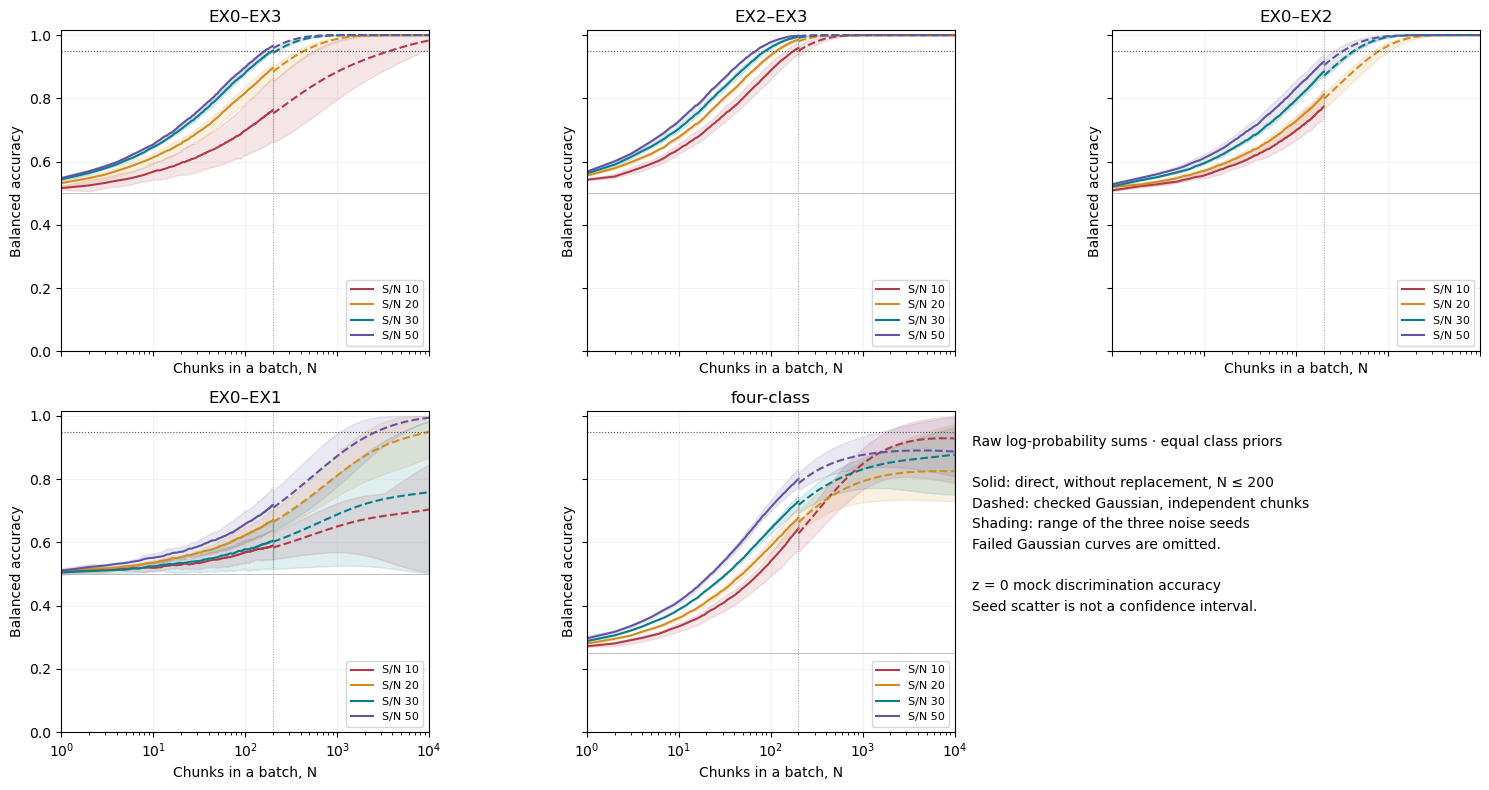

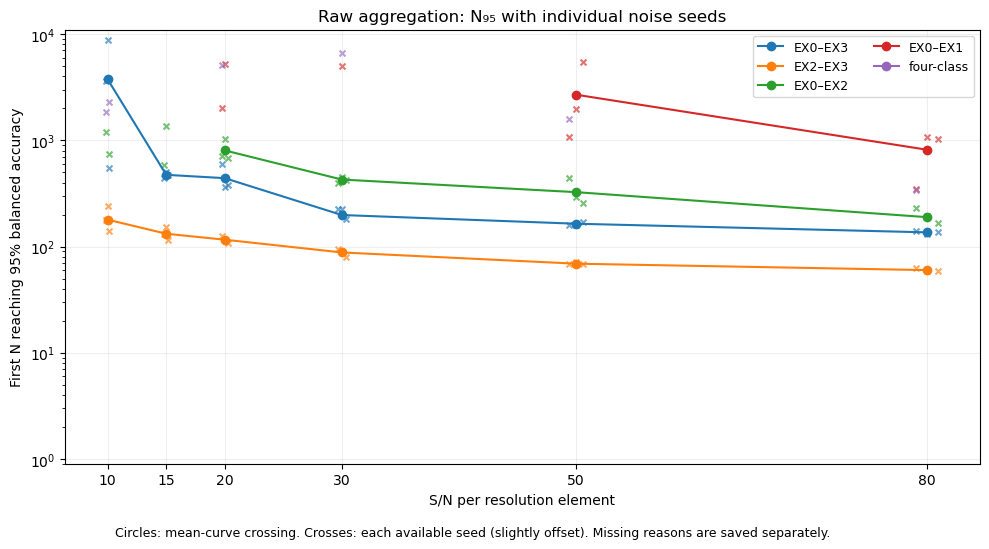

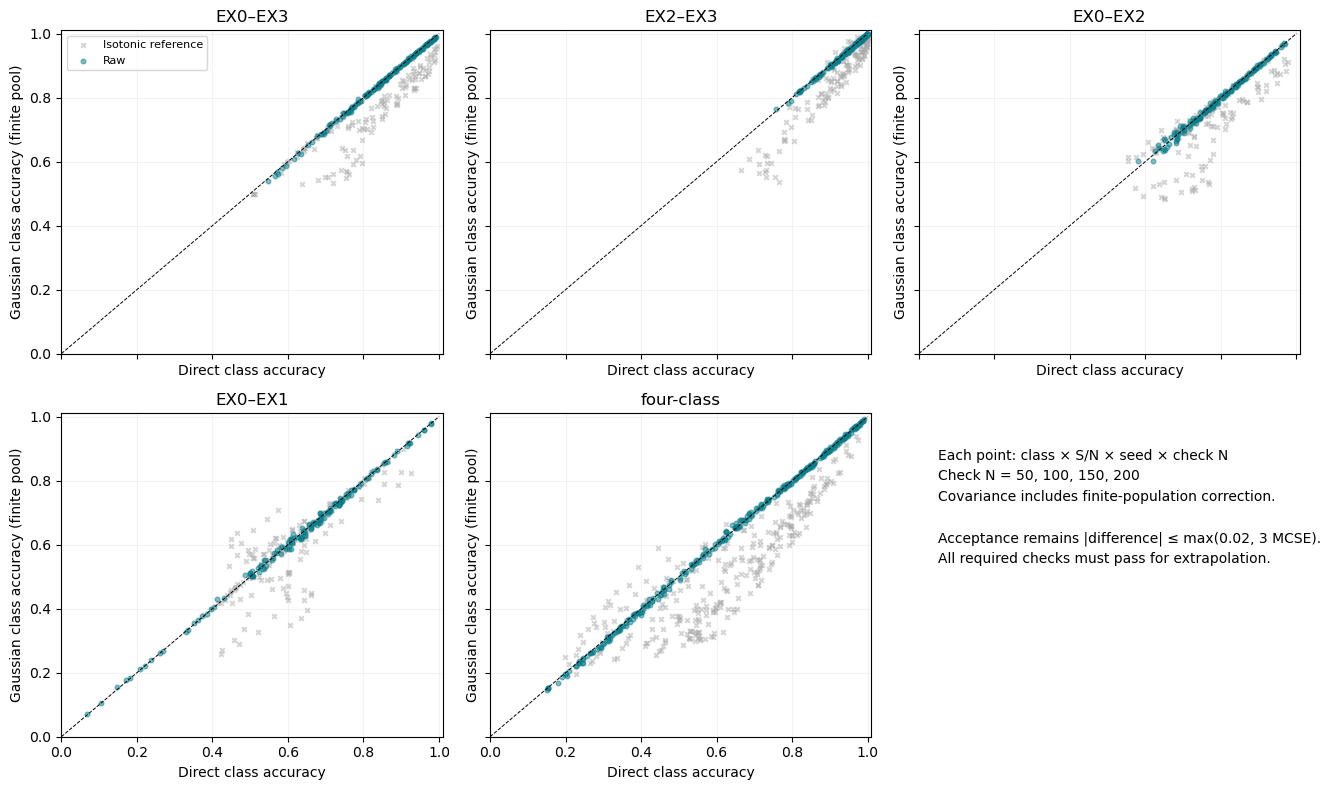

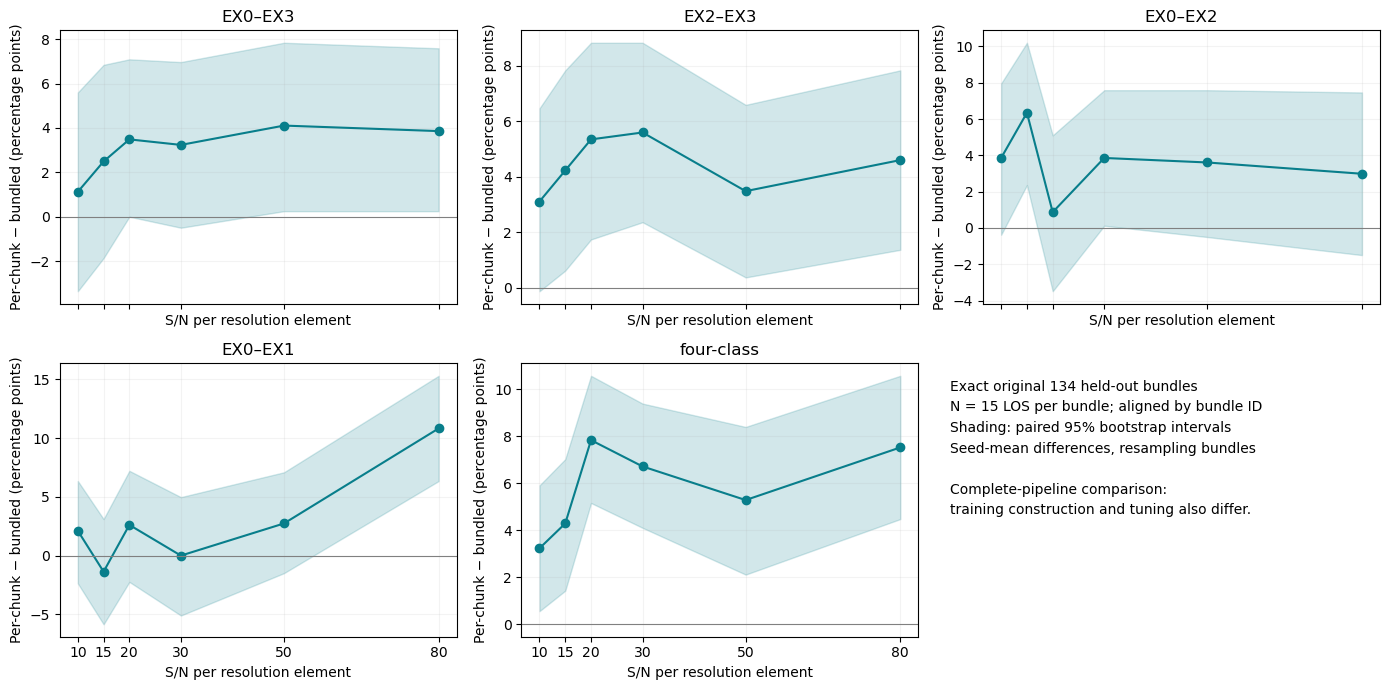


Raw versus isotonic: all classes, check sizes and three seeds required per task/SNR:


,source,gaussian_task_snr_passed,gaussian_task_snr_total,mean_curve_n95_available
0,raw,27,30,18
1,calibrated,4,30,6


Raw N95 (mean curve); all seed results and missing reasons are in the CSV files:


,task,snr,n95,method,missing_reasons,sustained_through_200_or_monotone
3,EX0_EX3,10,3745.0,gaussian_iid,,True
7,EX0_EX3,15,473.0,gaussian_iid,,True
11,EX0_EX3,20,440.0,gaussian_iid,,True
15,EX0_EX3,30,198.0,direct_first_crossing,,True
19,EX0_EX3,50,164.0,direct_first_crossing,,True
23,EX0_EX3,80,136.0,direct_first_crossing,,True
27,EX2_EX3,10,179.0,direct_first_crossing,,True
31,EX2_EX3,15,132.0,direct_first_crossing,,True
35,EX2_EX3,20,116.0,direct_first_crossing,,True
39,EX2_EX3,30,88.0,direct_first_crossing,,True


Exact N=15: complete pipelines, paired by the original bundle IDs:


,task,snr,per_chunk_accuracy,bundled_accuracy,difference,low,high
3,EX0_EX3,10,0.58209,0.57090,0.01119,-0.03358,0.05597
7,EX0_EX3,15,0.60199,0.57711,0.02488,-0.01866,0.06841
11,EX0_EX3,20,0.62562,0.59080,0.03483,-0.00000,0.07090
15,EX0_EX3,30,0.67164,0.63930,0.03234,-0.00498,0.06965
19,EX0_EX3,50,0.69652,0.65547,0.04104,0.00249,0.07836
23,EX0_EX3,80,0.70896,0.67040,0.03856,0.00249,0.07587
27,EX2_EX3,10,0.68035,0.64925,0.03109,-0.00124,0.06468
31,EX2_EX3,15,0.71517,0.67289,0.04229,0.00619,0.07836
35,EX2_EX3,20,0.72512,0.67164,0.05348,0.01741,0.08831
39,EX2_EX3,30,0.75124,0.69527,0.05597,0.02363,0.08831


Provisional raw S/N-only forecasts; final mask, retention and filling choices remain open:


,half_width_kms,scenario,task,n_chunks,expected_accuracy,seed_min,seed_max,failed_snr_bins
3,75,any_observed_bins,EX0_EX3,1025,0.999201,0.998898,0.999378,[]
7,75,any_observed_bins,EX2_EX3,1025,1.000000,1.000000,1.000000,[]
11,75,any_observed_bins,EX0_EX2,1025,NaN,NaN,NaN,"[10, 15]"
15,75,any_observed_bins,EX0_EX1,1025,0.812158,0.697580,0.881727,[]
35,75,at_least_half_observed,EX0_EX3,995,0.999111,0.998784,0.999301,[]
39,75,at_least_half_observed,EX2_EX3,995,1.000000,1.000000,1.000000,[]
43,75,at_least_half_observed,EX0_EX2,995,NaN,NaN,NaN,"[10, 15]"
47,75,at_least_half_observed,EX0_EX1,995,0.809893,0.696129,0.879153,[]
67,150,any_observed_bins,EX0_EX3,1025,0.999201,0.998898,0.999378,[]
71,150,any_observed_bins,EX2_EX3,1025,1.000000,1.000000,1.000000,[]


Completed in 1.6 minutes. Saved analysis: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/perchunk_tuned/raw_combination/analysis_20261018T231040039403Z


In [2]:
ANALYSIS_STEP_PATH = ROOT / "notebooks/raw_combination_analysis_step.py"
ANALYSIS_STEP_SOURCE = ANALYSIS_STEP_PATH.read_text(encoding="utf-8")
exec(compile(ANALYSIS_STEP_SOURCE, str(ANALYSIS_STEP_PATH), "exec"))